# 00 – Datenzugang (Phase 0)

Prüft für jede Datenquelle aus `PLAN.md`, dass sie lokal bzw. über Google Earth Engine **erreichbar** ist, und zählt die Kennzahlen für `DATA_SOURCES.md` direkt aus den Daten nach.
Rohdaten liegen unter `data/raw/` (nicht im Repository); Herkunft und Neu-Download stehen in `DATA_SOURCES.md`.

> **Österreich-Regel (PLAN.md §0):** Für österreichische Ertrags- und Satellitendaten werden hier nur Verfügbarkeit, Schema und Abdeckung geprüft – **keine Ertragswerte angezeigt oder ausgewertet**.

In [1]:
import re
import zipfile
from collections import defaultdict

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

from croptransfer.config import load_config, repo_path

cfg = load_config()
RAW = repo_path(cfg["paths"]["raw"])
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

## 1. Google Earth Engine – Szenen über Graz und Hickory Corners (Juli 2022)

`hls_s30_unfiltered` zeigt das Footprint-Artefakt der HLS-Kacheln an der Datumsgrenze (siehe `DECISIONS.md`).

In [2]:
from croptransfer import gee_extract

project = gee_extract.init_ee()
print("Projekt:", project)
pd.DataFrame(gee_extract.access_test(cfg)).T

Projekt: croptransfer


,hls_l30,hls_s30,s2_sr,s2_cloudscore,hls_s30_unfiltered
graz,4,12,13,13,200
hickory_corners_kbs,14,10,14,14,198


## 2. KBS LTER – MCSE-Parzellenerträge (Tabelle 51)

In [3]:
kbs = pd.read_csv(RAW / "kbs" / "kbs_datatable_51.csv", comment="#")
maize = kbs[kbs.Crop.str.contains("Zea", na=False) & kbs.whole_plot_yield_kg_ha.notna()].copy()
maize["plot_id"] = maize.Treatment + maize.Replicate
print("Mais-Parzellen-Jahre gesamt:", len(maize), "| Mais-Jahre:", maize.Year.nunique())
per_year = maize.groupby("Year").agg(n=("plot_id", "size"),
                                     mean_t_ha=("whole_plot_yield_kg_ha", lambda s: s.mean() / 1000))
display(per_year.round(2).T)
hls = maize[maize.Year >= cfg["years"]["groundtruth"][0]]
print("HLS-Zeit:", len(hls), "Parzellen-Jahre in", sorted(hls.Year.unique()),
      "| Parzellen:", hls["plot_id"].nunique())

Mais-Parzellen-Jahre gesamt: 295 | Mais-Jahre: 14


Year,1989,1990,1991,1993,1996,1999,2002,2005,2008,2011,2014,2017,2020,2023
n,12.00,12.00,8.00,24.00,23.00,24.00,24.00,24.00,24.00,24.00,24.00,24.00,24.00,24.00
mean_t_ha,8.01,4.59,8.18,5.63,3.46,4.08,5.64,7.19,5.15,10.21,8.89,7.05,7.84,9.15


HLS-Zeit: 96 Parzellen-Jahre in [np.int64(2014), np.int64(2017), np.int64(2020), np.int64(2023)] | Parzellen: 24


**Ertragstrend und RY-Normalwert** (Datenkritik §3.1 b): Der Normalwert für RY hängt davon ab, welche „anderen Jahre“ eingehen.

In [4]:
import numpy as np

slope = np.polyfit(per_year.index, per_year.mean_t_ha, 1)[0]
print(f"Linearer Trend über alle Mais-Jahre: {slope:+.3f} t/ha pro Jahr")

def relative_yield(df, pool_years):
    rows = []
    for (p, y), g in df.groupby(["plot_id", "Year"]):
        other = df[(df["plot_id"] == p) & (df.Year != y) & df.Year.isin(pool_years)]
        if other.Year.nunique() >= cfg["groundtruth"]["ry_min_other_years"]:
            rows.append({"plot": p, "Year": y, "Treatment": p[:2],
                         "RY": g.whole_plot_yield_kg_ha.mean() / other.whole_plot_yield_kg_ha.mean()})
    return pd.DataFrame(rows)

hls_years = sorted(hls.Year.unique())
thr = cfg["targets"]["at_risk_threshold"]
for name, pool in [("alle Mais-Jahre", maize.Year.unique()), ("nur HLS-Jahre", hls_years)]:
    r = relative_yield(maize, pool).query("Year in @hls_years")
    risk = r[r.RY < thr]
    print(f"{name:16s}: Median-RY je Jahr {r.groupby('Year').RY.median().round(2).to_dict()} | "
          f"RY<{thr}: {len(risk)} (je Jahr {risk.Year.value_counts().sort_index().to_dict()}, "
          f"je Behandlung {risk.Treatment.value_counts().sort_index().to_dict()})")

Linearer Trend über alle Mais-Jahre: +0.087 t/ha pro Jahr


alle Mais-Jahre : Median-RY je Jahr {2014: 1.35, 2017: 1.1, 2020: 1.21, 2023: 1.49} | RY<0.85: 12 (je Jahr {2014: 1, 2017: 6, 2020: 1, 2023: 4}, je Behandlung {'T1': 1, 'T4': 11})


nur HLS-Jahre   : Median-RY je Jahr {2014: 1.09, 2017: 0.83, 2020: 0.91, 2023: 1.18} | RY<0.85: 25 (je Jahr {2017: 13, 2020: 7, 2023: 5}, je Behandlung {'T1': 8, 'T2': 2, 'T3': 4, 'T4': 11})


## 3. USDA BARC – Kriging-Ertragskarten (Mais)

In [5]:
barc_fy = defaultdict(set)
for zpath in sorted((RAW / "barc").glob("20*.zip")):
    year = int(zpath.stem)
    for name in zipfile.ZipFile(zpath).namelist():
        m = re.match(rf"{year}/6A[^/]*/(.+)_{year}_corn_clip\.tif$", name, re.I)
        if m:  # normalise naming variants (USDA_ prefix, Central_Farm vs CentralFarm)
            key = m.group(1).lower().replace("usda_", "").replace("central_farm", "centralfarm")
            barc_fy[key].add(year)
n_years = pd.Series({k: len(v) for k, v in barc_fy.items()})
print("Mais-Feld-Jahre:", n_years.sum(), "| Felder (Namen normalisiert):", len(n_years))
print("Felder nach Anzahl Mais-Jahre:", n_years.value_counts().sort_index().to_dict())
print("Feld-Jahre mit definiertem RY (Feld hat >= 3 Mais-Jahre):", n_years[n_years >= 3].sum())
pd.Series({y: sum(y in v for v in barc_fy.values()) for y in range(2014, 2022)}, name="Mais-Karten").to_frame().T

Mais-Feld-Jahre: 62 | Felder (Namen normalisiert): 41
Felder nach Anzahl Mais-Jahre: {1: 28, 2: 9, 4: 4}
Feld-Jahre mit definiertem RY (Feld hat >= 3 Mais-Jahre): 16


,2014,2015,2016,2017,2018,2019,2020,2021
Mais-Karten,10,0,10,5,4,11,10,12


## 4. Colorado (Akron) – Ertragsstichproben

In [6]:
colo = pd.read_csv(RAW / "colorado" / "Modeling_data.csv")
cm = colo[colo.crop.str.lower().str.contains("corn|maize")]
units = cm.groupby(["field", "year"]).agg(n_points=("yield_kg_ha", "size"),
                                          mean_t_ha=("yield_kg_ha", lambda s: s.mean() / 1000))
display(units.round(2).T)
print("Mais-Jahre je Teilfläche:", cm.groupby("field").year.nunique().value_counts().to_dict(),
      "-> RY (>= 3 Mais-Jahre) nirgends definiert")

field,S2,S4,SB1,SB4,SB5,SB7,SCD2,SCD3,SCD5,SCD6
year,2019,2021,2022,2021,2019,2020,2021,2019,2020,2022
n_points,13.00,10.00,20.00,20.00,22.00,26.00,23.00,22.00,16.00,16.00
mean_t_ha,6.35,3.69,0.29,2.71,3.91,0.53,2.52,4.13,0.88,1.04


Mais-Jahre je Teilfläche: {1: 10} -> RY (>= 3 Mais-Jahre) nirgends definiert


## 5. Mead (AmeriFlux) – Status

In [7]:
print((RAW / "mead" / "STATUS.txt").read_text(encoding="utf-8"))

Mead, Nebraska (AmeriFlux US-Ne1 / US-Ne2 / US-Ne3) - Status 2026-10-15: angefragt / Konto noetig
Nothing downloaded. AmeriFlux BADM (BIF) download for a site:
  https://ameriflux.lbl.gov/data/download-data/?request=product:BIF;policy:CCBY4.0;site_id:US-Ne1  (same for US-Ne2, US-Ne3)
  -> anonymous request is redirected to https://ameriflux.lbl.gov/login/ (AmeriFlux account required).
Whether the BIF files contain grain yield (BADM groups BIOMASS / DM_AGRICULTURE) is NOT verified.
Site pages: https://ameriflux.lbl.gov/sites/siteinfo/US-Ne1 (Ne2, Ne3). Data policy: AmeriFlux CC-BY-4.0.



## 6. Ergänzende Quellen: One Acre Fund, YieldSAT, SSURGO

### 6a. One Acre Fund (Zenodo) – Kennzahlen und Vorab-Filter (PLAN §3.1)

Es werden keine Satellitendaten angesehen.

In [8]:
from croptransfer import one_acre_fund

oaf = one_acre_fund.summary(one_acre_fund.load(), cfg)
display(pd.Series(oaf["facts"], name="Wert").to_frame())
display(oaf["by_year"])
oaf["exact_by_year"]

,Wert
rows,14773
columns,53
years,"[2016, 2017, 2018, 2019, 2020, 2022]"
exact_location,10332
exact_share,0.699
coord_decimals,3
rounding_error_m,"(56, 56)"
field_size_column,None
moisture_column,None
exact_sharing_point,1254


year,2016,2017,2018,2019,2020,2022,Summe
country,,,,,,,
burundi,142,173,0,194,131,0,640
kenya,1111,921,1180,1755,2291,0,7258
nigeria,0,0,0,0,0,115,115
rwanda,0,0,556,608,916,0,2080
tanzania,1184,0,985,1381,160,0,3710
uganda,0,0,0,0,109,0,109
zambia,0,0,466,395,0,0,861
Summe,2437,1094,3187,4333,3607,115,14773


year,2016,2017,2018,2019,2020,2022
country,,,,,,
burundi,0,138,0,0,0,0
kenya,1084,921,1175,1739,2151,0
nigeria,0,0,0,0,0,115
rwanda,0,0,0,130,363,0
tanzania,0,0,655,894,159,0
uganda,0,0,0,0,109,0
zambia,0,0,304,395,0,0


### 6b. YieldSAT

Zugang beantragt der Projektinhaber über das Formular auf yieldsat.github.io. Bis dahin sind keine Daten lokal vorhanden (Status in `DATA_SOURCES.md` §10).

### 6c. SSURGO (Soil Data Access, ohne Login) – Testabfrage KBS-Parzellen und BARC 1-7

In [9]:
from croptransfer import soil_ssurgo

ssurgo_rows = []
for name, wkt in soil_ssurgo._test_fields(cfg).items():
    vals, _ = soil_ssurgo.query_field(wkt, cfg)
    ssurgo_rows.append({"Feld": name, **vals})
ssurgo_table = pd.DataFrame(ssurgo_rows).set_index("Feld")
print("NCCPI Mais je Feld (eindeutige Werte):", ssurgo_table.nccpi_corn.round(3).unique())
ssurgo_table.round(3).tail(3)

NCCPI Mais je Feld (eindeutige Werte): [0.664 0.507]


,nonirryield_r,nonirryield_r_comp_pct,nccpi_corn,nccpi_corn_comp_pct,n_mapunits
Feld,,,,,
KBS T2R4,NaN,1.000,0.664,100.000,1
KBS T1R2,NaN,1.000,0.664,100.000,1
BARC CentralFarm 1-7,116.497,76.081,0.507,77.418,5


## 7. INVEKOS Schläge (AMA) – nur Schema und Zählung

Österreich-Regel: Es werden nur Dateien, Spalten und Anzahlen geprüft. Die Steiermark-Zuordnung erfolgt über den repräsentativen Punkt jedes Schlags in den Gemeinden (Stand 2025-01-01).

In [10]:
from croptransfer import invekos

gpkgs = invekos.find_gpkgs(RAW / "invekos")
schemas = {y: invekos.schema(p) for y, p in gpkgs.items()}
pd.DataFrame({y: {"Datei": gpkgs[y].name, "Schläge": s["features"],
                  "CRS": str(s["crs"])[:40], "Spalten": len(s["columns"]),
                  "SNAR_CODE": "SNAR_CODE" in s["columns"],
                  "SNAR_BEZEICHNUNG": "SNAR_BEZEICHNUNG" in s["columns"]}
              for y, s in schemas.items()}).T

,Datei,Schläge,CRS,Spalten,SNAR_CODE,SNAR_BEZEICHNUNG
2018,INSPIRE_SCHLAEGE_2018_POLYGON.gpkg,2523190,"PROJCS[""MGI / Austria Lambert"",GEOGCS[""M",15,True,True
2019,INSPIRE_SCHLAEGE_2019_POLYGON.gpkg,2529896,"PROJCS[""MGI / Austria Lambert"",GEOGCS[""M",15,True,True
2020,INSPIRE_SCHLAEGE_2020_POLYGON.gpkg,2614636,"PROJCS[""MGI / Austria Lambert"",GEOGCS[""M",15,True,True
2021,INSPIRE_SCHLAEGE_2021_POLYGON.gpkg,2610510,EPSG:31287,15,True,True
2022,INSPIRE_SCHLAEGE_2022-2_POLYGON.gpkg,2603946,EPSG:31287,16,True,True
2023,INSPIRE_SCHLAEGE_2023-2_POLYGON.gpkg,2947738,EPSG:31287,16,True,True
2024,INSPIRE_SCHLAEGE_2024-2_POLYGON.gpkg,2956434,EPSG:31287,16,True,True
2025,INSPIRE_SCHLAEGE_2025-2_POLYGON.gpkg,2949054,EPSG:31287,16,True,True


In [11]:
cols = {y: set(s["columns"]) for y, s in schemas.items()}
common = set.intersection(*cols.values())
print("Gemeinsame Spalten:", sorted(common))
for y, c in cols.items():
    if c - common:
        print(f"{y}: zusätzlich {sorted(c - common)}")

Gemeinsame Spalten: ['FART_ID', 'FS_KENNUNG', 'GEOM_DATE_CREATED', 'GEO_ID', 'GEO_PART_KEY', 'GEO_TYPE', 'GML_GEOM', 'GML_ID', 'GML_IDENTIFIER', 'GML_LENGTH', 'INSPIRE_ID', 'LOG_PKEY', 'SL_FLAECHE_BRUTTO_HA', 'SNAR_BEZEICHNUNG', 'SNAR_CODE']
2022: zusätzlich ['KZ_BIO_OEPUL_JN']
2023: zusätzlich ['KZ_BIO_OEPUL_JN']
2024: zusätzlich ['KZ_BIO_OEPUL_JN']
2025: zusätzlich ['KZ_BIO_OEPUL_JN']


In [12]:
codes = {"105": "Körnermais", "106": "CCM", "109": "Silomais", "173": "Saatmaisvermehrung",
         "175": "Wintergerste/Körnermais"}
gem = gpd.read_file(next((RAW / "admin_at" / "GEM_20250101").glob("*.shp")))
rows = []
for y, p in gpkgs.items():
    c = invekos.crop_code_counts(p, codes)
    st = invekos.count_in_state(p, gem, code="105", min_area_ha=cfg["field"]["min_area_ha"])
    rows.append({"Jahr": y, **{f"n {codes[k]}": int(c.loc[k, "n"]) for k in codes},
                 "Körnermais Stmk n": st["n"], f"Stmk ≥ {cfg['field']['min_area_ha']} ha": st["n_ge_min_area"],
                 "ungültige Geom. (Körnermais AT)": st["invalid_geometries"], "ohne Gemeinde": st["unmatched"]})
invekos_counts = pd.DataFrame(rows).set_index("Jahr")
invekos_counts

,n Körnermais,n CCM,n Silomais,n Saatmaisvermehrung,n Wintergerste/Körnermais,Körnermais Stmk n,Stmk ≥ 1.0 ha,ungültige Geom. (Körnermais AT),ohne Gemeinde
Jahr,,,,,,,,,
2018,107154,10590,55120,2597,0,33764,12299,0,0
2019,112095,11319,55753,2922,2,36822,13140,0,0
2020,106667,11265,56475,2987,8,34464,12347,0,0
2021,110175,10874,54482,3261,6,35605,12907,0,0
2022,109413,9995,53309,3001,8,35236,13079,0,0
2023,113212,8966,51488,3092,32,37934,14027,0,0
2024,107687,8358,51624,2757,60,36808,13933,1,0
2025,114509,8307,52746,3131,37,39264,14726,0,0


## 8. Verwaltungsgrenzen Österreich (Statistik Austria)

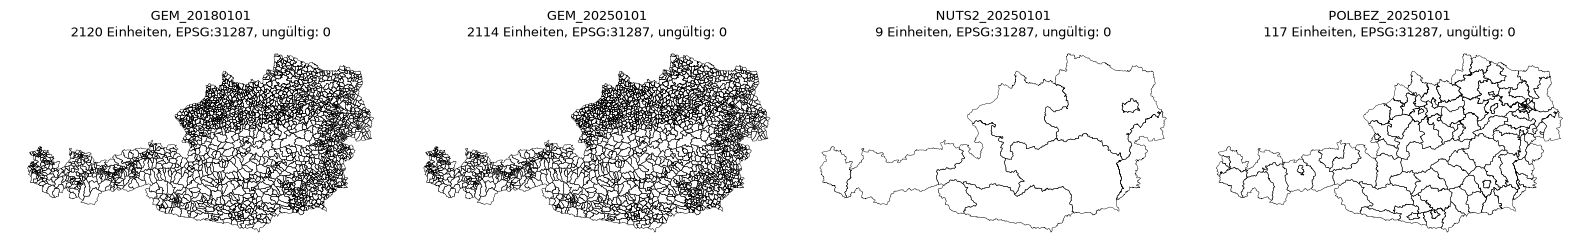

In [13]:
admin = {p.name: next(p.glob("*.shp")) for p in sorted((RAW / "admin_at").iterdir()) if p.is_dir()}
fig, axes = plt.subplots(1, len(admin), figsize=(4 * len(admin), 3))
for ax, (name, shp) in zip(axes, admin.items()):
    g = gpd.read_file(shp)
    g.boundary.plot(ax=ax, linewidth=0.3, color="k")
    ax.set_title(f"{name}\n{len(g)} Einheiten, EPSG:{g.crs.to_epsg()}, ungültig: {(~g.is_valid).sum()}", fontsize=9)
    ax.set_axis_off()
plt.tight_layout()

## 9. CY-Bench v1.10 – Mais

EU-Länder mit Abdeckung; für Österreich nur Schema und Abdeckung (Österreich-Regel).

In [14]:
cyb_dir = RAW / "cybench" / "cybench-data" / "maize"
eu = []
for d in sorted(cyb_dir.iterdir()):
    y = pd.read_csv(d / f"yield_maize_{d.name}.csv")
    pos = y[y["yield"] > 0]
    eu.append({"Land": d.name, "Regionen": y.adm_id.nunique(),
               "Jahre": f"{pos.harvest_year.min()}–{pos.harvest_year.max()}" if len(pos) else "–",
               "Region-Jahre (Ertrag>0)": len(pos), "Nullerträge": int((y["yield"] == 0).sum())})
pd.DataFrame(eu).set_index("Land").T

Land,AT,BE,BG,CZ,DE,DK,EE,EL,ES,FI,FR,HR,HU,IE,IT,LT,LV,NL,PL,PT,RO,SE,SK
Regionen,9,11,6,14,372,7,5,52,53,19,95,2,20,3,103,10,6,12,17,7,42,1,8
Jahre,1975–2020,2011–2020,1991–2020,2005–2020,1979–2021,2011–2020,–,2009–2019,1998–2020,–,1989–2020,2005–2020,1996–2020,–,1995–2020,2002–2020,–,2008–2020,2003–2020,1986–2020,1998–2020,2007–2020,2007–2018
Region-Jahre (Ertrag>0),414,85,180,212,9095,22,0,492,1145,0,2940,32,459,0,2325,159,0,126,301,230,942,10,94
Nullerträge,0,1,0,4,0,0,105,67,1,399,86,0,0,63,0,22,126,3,0,13,4,0,0


In [15]:
at_files = sorted(p.name for p in (cyb_dir / "AT").glob("*.csv"))
cyb_at = pd.read_csv(cyb_dir / "AT" / "yield_maize_AT.csv")
print("AT-Dateien:", at_files)
print("AT-Ertrag: Spalten", list(cyb_at.columns), "| Regionen", sorted(cyb_at.adm_id.unique()),
      "| Jahre", cyb_at.harvest_year.min(), "-", cyb_at.harvest_year.max(),
      "| Zeilen", len(cyb_at), "| fehlend", int(cyb_at["yield"].isna().sum()))

AT-Dateien: ['crop_calendar_maize_AT.csv', 'crop_mask_maize_AT.csv', 'fpar_maize_AT.csv', 'location_maize_AT.csv', 'meteo_maize_AT.csv', 'ndvi_maize_AT.csv', 'soil_maize_AT.csv', 'soil_moisture_maize_AT.csv', 'yield_maize_AT.csv']
AT-Ertrag: Spalten ['crop_name', 'country_code', 'adm_id', 'harvest_year', 'yield', 'harvest_area', 'production'] | Regionen ['AT11', 'AT12', 'AT13', 'AT21', 'AT22', 'AT31', 'AT32', 'AT33', 'AT34'] | Jahre 1975 - 2020 | Zeilen 414 | fehlend 0


## 10. Statistik Austria – `stat_at_maize.csv` (nur Schema und Abdeckung)

In [16]:
stat = pd.read_csv(RAW / "stat_at_maize.csv")
print("Spalten:", list(stat.columns), "| Zeilen:", len(stat))
display(pd.crosstab(stat.year, stat.status).T)
print("fehlende Erträge:", int(stat.yield_t_ha.isna().sum()),
      "| Bundesländer:", stat.bundesland.nunique())

Spalten: ['year', 'bundesland', 'area_ha', 'yield_t_ha', 'production_t', 'source', 'status', 'notes'] | Zeilen: 170


year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
status,,,,,,,,,,,,,,,,,
endgültig,10,10,10,10,10,10,10,10,10,10,10,10,10,10,10,10,0
vorläufig,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,10


fehlende Erträge: 0 | Bundesländer: 10


## 11. Österreichische Versuchsberichte – `at_trials.csv` (nur Bestand, keine Erträge)

In [17]:
trials = pd.read_csv(RAW / "at_trials.csv")
print("Spalten:", list(trials.columns), "| Zeilen:", len(trials))
trials.groupby(["bundesland", "site"]).year.agg(["count", "min", "max"])

Spalten: ['site', 'bundesland', 'lat', 'lon', 'loc_precision', 'year', 'yield_t_ha', 'moisture_basis', 'trial_type', 'variant', 'sowing_date', 'harvest_date', 'source_pdf', 'page', 'notes'] | Zeilen: 150


count   min   max
bundesland     site                                                   
Oberösterreich Aistersheim                               2  2023  2024
               Bad Wimsbach                              3  2020  2022
               Bad Wimsbach-Neydharting                  8  2015  2026
               Dietach                                   1  2025  2025
               Eberstalzell                              1  2024  2024
               Enns                                      1  2022  2022
               Geinberg                                  2  2026  2026
               Geinberg/Katzenberg                       1  2025  2025
               Katzenberg                                4  2020  2024
               Katzenberg bei Kirchdorf/I.               3  2013  2015
               Kirchdorf am Inn                          1  2018  2018
               Kirchdorf/Inn                             2  2016  2017
               Leonding                                  3  2013  2016
               Leonding/Hörsching                        2  2014  2017
               Linden                                    5  2020  2024
               Linden (Steinerkirchen an der Traun)      1  2018  2018
               Linden (Steinerkirchen/Tr.)               1  2013  2013
               Linden (Steinerkirchen/Traun)             2  2014  2015
               Linden/Steinerkirchen an der Traun        1  2026  2026
               Mauthausen                               22  2013  2025
               Nußbach                                   1  2013  2013
               Pasching                                  1  2018  2018
               Steinerkirchen/Linden                     3  2016  2025
               Walding                                  35  2014  2026
Steiermark     Hatzendorf                                3  2019  2024
               Kalsdorf bei Ilz                         14  2013  2024
               Kühwiesen (St. Ruprecht an der Raab)      1  2017  2017
               Unterhatzendorf (Hatzendorf)              1  2017  2017
               Wagendorf (St. Veit am Vogau)             1  2013  2013
               Wagna                                    23  2012  2024
               Wollsdorf (St. Ruprecht an der Raab)      1  2016  2016

## Zusammenfassung

Status je Quelle und Befunde: `DATA_SOURCES.md` (Übersicht) und `reports/data_review/phase0_data_access.md`.